In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd

matches = pd.read_csv("./datasets/matches.csv")

In [3]:
matches.isna().sum()

Unnamed: 0         0
date               0
time               0
comp               0
round              0
day                0
venue              0
result             0
gf                 0
ga                 0
opponent           0
xg                 0
xga                0
poss               0
attendance       696
captain            0
formation          0
referee            0
match report       0
notes           1389
sh                 0
sot                0
dist               1
fk                 0
pk                 0
pkatt              0
season             0
team               0
dtype: int64

In [4]:
matches.shape

(1389, 28)

In [5]:
matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 1389 entries, 0 to 1388
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1389 non-null   int64  
 1   date          1389 non-null   str    
 2   time          1389 non-null   str    
 3   comp          1389 non-null   str    
 4   round         1389 non-null   str    
 5   day           1389 non-null   str    
 6   venue         1389 non-null   str    
 7   result        1389 non-null   str    
 8   gf            1389 non-null   float64
 9   ga            1389 non-null   float64
 10  opponent      1389 non-null   str    
 11  xg            1389 non-null   float64
 12  xga           1389 non-null   float64
 13  poss          1389 non-null   float64
 14  attendance    693 non-null    float64
 15  captain       1389 non-null   str    
 16  formation     1389 non-null   str    
 17  referee       1389 non-null   str    
 18  match report  1389 non-null   str    
 

In [6]:
matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 1389 entries, 0 to 1388
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1389 non-null   int64  
 1   date          1389 non-null   str    
 2   time          1389 non-null   str    
 3   comp          1389 non-null   str    
 4   round         1389 non-null   str    
 5   day           1389 non-null   str    
 6   venue         1389 non-null   str    
 7   result        1389 non-null   str    
 8   gf            1389 non-null   float64
 9   ga            1389 non-null   float64
 10  opponent      1389 non-null   str    
 11  xg            1389 non-null   float64
 12  xga           1389 non-null   float64
 13  poss          1389 non-null   float64
 14  attendance    693 non-null    float64
 15  captain       1389 non-null   str    
 16  formation     1389 non-null   str    
 17  referee       1389 non-null   str    
 18  match report  1389 non-null   str    
 

In [7]:
matches["date"] = pd.to_datetime(matches["date"])

In [8]:
# sort in chronological order
matches = matches.sort_values(by=["team", "date"], ignore_index=True)

In [9]:
matches.isna().sum()

Unnamed: 0         0
date               0
time               0
comp               0
round              0
day                0
venue              0
result             0
gf                 0
ga                 0
opponent           0
xg                 0
xga                0
poss               0
attendance       696
captain            0
formation          0
referee            0
match report       0
notes           1389
sh                 0
sot                0
dist               1
fk                 0
pk                 0
pkatt              0
season             0
team               0
dtype: int64

In [10]:
matches = matches.drop(columns=["attendance", "Unnamed: 0"])

In [11]:
matches.isna().sum()

date               0
time               0
comp               0
round              0
day                0
venue              0
result             0
gf                 0
ga                 0
opponent           0
xg                 0
xga                0
poss               0
captain            0
formation          0
referee            0
match report       0
notes           1389
sh                 0
sot                0
dist               1
fk                 0
pk                 0
pkatt              0
season             0
team               0
dtype: int64

In [12]:
matches = matches.drop(columns=["notes"])

In [17]:
matches.isna().sum()

date            0
time            0
comp            0
round           0
day             0
venue           0
result          0
gf              0
ga              0
opponent        0
xg              0
xga             0
poss            0
captain         0
formation       0
referee         0
match report    0
sh              0
sot             0
dist            1
fk              0
pk              0
pkatt           0
season          0
team            0
dtype: int64

In [14]:
# split chronologically
from src import split as spl

train, valid, test = spl.split_data(matches)

In [15]:
test.tail()

,date,time,comp,round,day,venue,result,gf,ga,opponent,...,referee,match report,sh,sot,dist,fk,pk,pkatt,season,team
1384,2022-03-13,14:00,Premier League,Matchweek 29,Sun,Away,W,1.0,0.0,Everton,...,Michael Oliver,Match Report,14.0,3.0,20.7,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1385,2022-03-18,20:00,Premier League,Matchweek 30,Fri,Home,L,2.0,3.0,Leeds United,...,Kevin Friend,Match Report,14.0,8.0,20.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1386,2022-04-02,15:00,Premier League,Matchweek 31,Sat,Home,W,2.0,1.0,Aston Villa,...,Darren England,Match Report,11.0,4.0,14.3,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1387,2022-04-08,20:00,Premier League,Matchweek 32,Fri,Away,L,0.0,1.0,Newcastle Utd,...,Peter Bankes,Match Report,5.0,2.0,18.0,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1388,2022-04-24,14:00,Premier League,Matchweek 34,Sun,Away,L,0.0,1.0,Burnley,...,Anthony Taylor,Match Report,10.0,4.0,18.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers


In [19]:
# features to use

features = ["team", "opponent", "venue"]

In [20]:
X_train, y_train = spl.split_label(train, features)
X_valid, y_valid = spl.split_label(valid, features)
X_test, y_test = spl.split_label(test, features)

In [ ]:
results_label = {"W": 0, "L": 1, "D": 2}

y_train_encoded = y_train.map(results_label)
y_valid_encoded = y_valid.map(results_label)
y_test_encoded = y_test.map(results_label)

In [37]:
y_train_encoded

0       0
1       0
2       1
3       0
4       1
       ..
1362    0
1363    0
1364    2
1365    0
1366    1
Name: result, Length: 969, dtype: int64

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore").set_output(
    transform="pandas"
)

X_train_encoded = encoder.fit_transform(X_train)
X_valid_encoded = encoder.transform(X_valid)
X_test_encoded = encoder.transform(X_test)

In [29]:
X_train_encoded

,team_Arsenal,team_Aston Villa,team_Brentford,team_Brighton and Hove Albion,team_Burnley,team_Chelsea,team_Crystal Palace,team_Everton,team_Fulham,team_Leeds United,...,opponent_Norwich City,opponent_Sheffield Utd,opponent_Southampton,opponent_Tottenham,opponent_Watford,opponent_West Brom,opponent_West Ham,opponent_Wolves,venue_Away,venue_Home
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1363,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1364,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Logistic Regression


In [30]:
# first training
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_encoded, y_train_encoded)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [31]:
predictions = log_reg.predict(X_valid_encoded)

In [44]:
from src import evaluation as eval

eval.evaluate(y_valid_encoded, predictions)

Accuracy: 0.51707


In [45]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_valid_encoded,
        predictions,
        labels=[0, 1, 2],
        target_names=["Win", "Loss", "Draw"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

         Win       0.51      0.68      0.58        71
        Loss       0.54      0.69      0.61        78
        Draw       0.36      0.07      0.12        56

    accuracy                           0.52       205
   macro avg       0.47      0.48      0.44       205
weighted avg       0.48      0.52      0.46       205



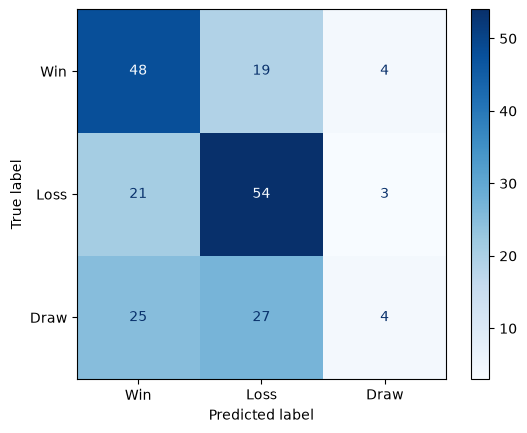

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_valid_encoded,
    predictions,
    labels=[0, 1, 2],
    display_labels=["Win", "Loss", "Draw"],
    cmap="Blues",
)

plt.show()

In [48]:
matches

,date,time,comp,round,day,venue,result,gf,ga,opponent,...,referee,match report,sh,sot,dist,fk,pk,pkatt,season,team
0,2020-09-12,12:30,Premier League,Matchweek 1,Sat,Away,W,3.0,0.0,Fulham,...,Chris Kavanagh,Match Report,13.0,5.0,13.6,2.0,0.0,0.0,2021,Arsenal
1,2020-09-19,20:00,Premier League,Matchweek 2,Sat,Home,W,2.0,1.0,West Ham,...,Michael Oliver,Match Report,6.0,3.0,15.3,0.0,0.0,0.0,2021,Arsenal
2,2020-09-28,20:00,Premier League,Matchweek 3,Mon,Away,L,1.0,3.0,Liverpool,...,Craig Pawson,Match Report,4.0,3.0,15.3,0.0,0.0,0.0,2021,Arsenal
3,2020-10-04,14:00,Premier League,Matchweek 4,Sun,Home,W,2.0,1.0,Sheffield Utd,...,Lee Mason,Match Report,6.0,5.0,16.7,0.0,0.0,0.0,2021,Arsenal
4,2020-10-17,17:30,Premier League,Matchweek 5,Sat,Away,L,0.0,1.0,Manchester City,...,Chris Kavanagh,Match Report,11.0,3.0,18.2,2.0,0.0,0.0,2021,Arsenal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1384,2022-03-13,14:00,Premier League,Matchweek 29,Sun,Away,W,1.0,0.0,Everton,...,Michael Oliver,Match Report,14.0,3.0,20.7,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1385,2022-03-18,20:00,Premier League,Matchweek 30,Fri,Home,L,2.0,3.0,Leeds United,...,Kevin Friend,Match Report,14.0,8.0,20.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1386,2022-04-02,15:00,Premier League,Matchweek 31,Sat,Home,W,2.0,1.0,Aston Villa,...,Darren England,Match Report,11.0,4.0,14.3,0.0,0.0,0.0,2022,Wolverhampton Wanderers
1387,2022-04-08,20:00,Premier League,Matchweek 32,Fri,Away,L,0.0,1.0,Newcastle Utd,...,Peter Bankes,Match Report,5.0,2.0,18.0,0.0,0.0,0.0,2022,Wolverhampton Wanderers


In [55]:
# add gf ga xg xga as features
# for each team - add a rolling average column 
# for each feature considering past 5 matches

from src import stats

matches = stats.compute_rolling(matches)

In [58]:
matches

,date,time,comp,round,day,venue,result,gf,ga,opponent,...,dist,fk,pk,pkatt,season,team,rolling_gf,rolling_ga,rolling_xg,rolling_xga
0,2020-09-12,12:30,Premier League,Matchweek 1,Sat,Away,W,3.0,0.0,Fulham,...,13.6,2.0,0.0,0.0,2021,Arsenal,NaN,NaN,NaN,NaN
1,2020-09-19,20:00,Premier League,Matchweek 2,Sat,Home,W,2.0,1.0,West Ham,...,15.3,0.0,0.0,0.0,2021,Arsenal,3.0,0.000000,1.800000,0.200000
2,2020-09-28,20:00,Premier League,Matchweek 3,Mon,Away,L,1.0,3.0,Liverpool,...,15.3,0.0,0.0,0.0,2021,Arsenal,2.5,0.500000,1.600000,1.050000
3,2020-10-04,14:00,Premier League,Matchweek 4,Sun,Home,W,2.0,1.0,Sheffield Utd,...,16.7,0.0,0.0,0.0,2021,Arsenal,2.0,1.333333,1.466667,1.766667
4,2020-10-17,17:30,Premier League,Matchweek 5,Sat,Away,L,0.0,1.0,Manchester City,...,18.2,2.0,0.0,0.0,2021,Arsenal,2.0,1.250000,1.200000,1.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1384,2022-03-13,14:00,Premier League,Matchweek 29,Sun,Away,W,1.0,0.0,Everton,...,20.7,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.200000,0.760000,1.980000
1385,2022-03-18,20:00,Premier League,Matchweek 30,Fri,Home,L,2.0,3.0,Leeds United,...,20.6,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.2,1.000000,0.800000,1.760000
1386,2022-04-02,15:00,Premier League,Matchweek 31,Sat,Home,W,2.0,1.0,Aston Villa,...,14.3,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.4,1.200000,0.760000,1.660000
1387,2022-04-08,20:00,Premier League,Matchweek 32,Fri,Away,L,0.0,1.0,Newcastle Utd,...,18.0,0.0,0.0,0.0,2022,Wolverhampton Wanderers,1.8,1.200000,0.840000,1.660000


In [65]:
rolling_cols = [
    "rolling_gf",
    "rolling_ga",
    "rolling_xg",
    "rolling_xga",
]

In [75]:
features = ["team", "opponent", "venue", *rolling_cols]

(
    X_train_encoded,
    X_valid_encoded,
    X_test_encoded,
    y_train_encoded,
    y_valid_encoded,
    y_test_encoded,
) = spl.final_split(matches, features, encoder)

In [79]:
X_train_encoded.head()

,team_Arsenal,team_Aston Villa,team_Brentford,team_Brighton and Hove Albion,team_Burnley,team_Chelsea,team_Crystal Palace,team_Everton,team_Fulham,team_Leeds United,...,opponent_Watford,opponent_West Brom,opponent_West Ham,opponent_Wolves,venue_Away,venue_Home,rolling_gf,rolling_ga,rolling_xg,rolling_xga
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN,NaN
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,3.0,0.000000,1.800000,0.200000
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2.5,0.500000,1.600000,1.050000
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2.0,1.333333,1.466667,1.766667
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,1.250000,1.200000,1.375000


In [80]:
# dealing with null values
from sklearn.impute import SimpleImputer


imputer = SimpleImputer(strategy="median")

X_train_encoded[rolling_cols] = imputer.fit_transform(X_train_encoded[rolling_cols])
X_valid_encoded[rolling_cols] = imputer.transform(X_valid_encoded[rolling_cols])
X_test_encoded[rolling_cols] = imputer.transform(X_test_encoded[rolling_cols])

In [81]:
X_train_encoded.isna().sum()

team_Arsenal                     0
team_Aston Villa                 0
team_Brentford                   0
team_Brighton and Hove Albion    0
team_Burnley                     0
team_Chelsea                     0
team_Crystal Palace              0
team_Everton                     0
team_Fulham                      0
team_Leeds United                0
team_Leicester City              0
team_Liverpool                   0
team_Manchester City             0
team_Manchester United           0
team_Newcastle United            0
team_Norwich City                0
team_Sheffield United            0
team_Southampton                 0
team_Tottenham Hotspur           0
team_Watford                     0
team_West Bromwich Albion        0
team_West Ham United             0
team_Wolverhampton Wanderers     0
opponent_Arsenal                 0
opponent_Aston Villa             0
opponent_Brentford               0
opponent_Brighton                0
opponent_Burnley                 0
opponent_Chelsea    

In [82]:
log_reg.fit(X_train_encoded, y_train_encoded)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Accuracy: 0.50732
              precision    recall  f1-score   support

         Win       0.50      0.65      0.56        71
        Loss       0.51      0.68      0.59        78
        Draw       0.50      0.09      0.15        56

    accuracy                           0.51       205
   macro avg       0.50      0.47      0.43       205
weighted avg       0.51      0.51      0.46       205



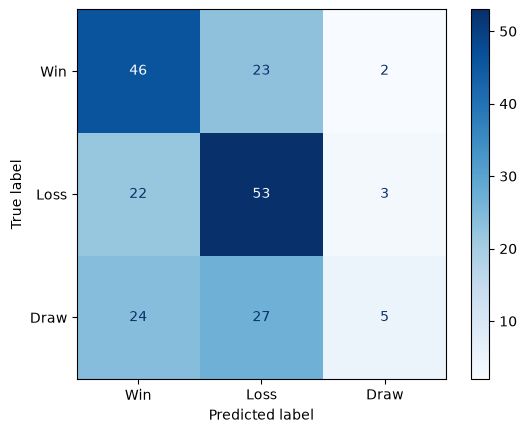

In [84]:
eval.evaluate(log_reg, X_valid_encoded, y_valid_encoded, predictions)

In [91]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)

forest.fit(X_train_encoded, y_train_encoded)

predictions = forest.predict(X_valid_encoded)

Accuracy: 0.48293
              precision    recall  f1-score   support

         Win       0.49      0.54      0.51        71
        Loss       0.48      0.78      0.60        78
        Draw       0.00      0.00      0.00        56

    accuracy                           0.48       205
   macro avg       0.32      0.44      0.37       205
weighted avg       0.35      0.48      0.40       205



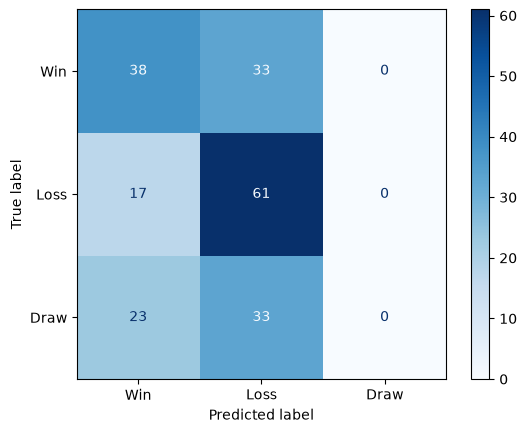

In [92]:
eval.evaluate(forest, X_valid_encoded, y_valid_encoded, predictions)

In [93]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from src import split as spl

categorical_cols = ["team", "opponent", "venue"]
rolling_cols = ["rolling_gf", "rolling_ga", "rolling_xg", "rolling_xga"]
features = categorical_cols + rolling_cols

# Use features before encoding or filling missing values
train_cv, valid_cv, _ = spl.split_data(matches)

X_cv = train_cv[features]
label_map = {"W": 0, "L": 1, "D": 2}
y_cv = train_cv["result"].map(label_map)

# Chronological folds, keeping each date together
match_dates = np.sort(train_cv["date"].unique())
cv = []

for past, future in TimeSeriesSplit(n_splits=3).split(match_dates):
    train_indices = np.flatnonzero(
        train_cv["date"].isin(match_dates[past])
    )
    valid_indices = np.flatnonzero(
        train_cv["date"].isin(match_dates[future])
    )
    cv.append((train_indices, valid_indices))

preprocess = ColumnTransformer([
    (
        "categories",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_cols,
    ),
    (
        "numbers",
        SimpleImputer(strategy="median"),
        rolling_cols,
    ),
])

pipeline = Pipeline([
    ("preprocess", preprocess),
    ("forest", RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=1,
    )),
])

In [94]:
param_grid = {
    "forest__max_depth": [10, 20, None],
    "forest__min_samples_leaf": [1, 5],
    "forest__max_features": ["sqrt", 1.0],
}

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    error_score="raise",
)

search.fit(X_cv, y_cv)

best_forest = search.best_estimator_

print("Best parameters:", search.best_params_)
print("Best average CV macro F1:", search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'forest__max_depth': None, 'forest__max_features': 'sqrt', 'forest__min_samples_leaf': 1}
Best average CV macro F1: 0.39948068132667175
